# Predicción de la demanda de bicicletas compartidas
**IA006 - Inteligencia Artificial - Proyecto segundo corte (implementación)**

María Alejandra Suárez Muñoz - Johan Sebastián Valderrama

Docente: Ph.D. Andrés Felipe Jerez Ariza

## 1. Contexto y continuidad

**Contexto.** Capital Bikeshare es un sistema de bicicletas compartidas en Washington D.C. Si en una hora faltan bicicletas se pierden usuarios, y si sobran se gasta en moverlas entre estaciones. Saber cuántas bicicletas se van a alquilar en cada hora permite decidir cuántas tener disponibles.

**Problema.** ¿Cuántas bicicletas se alquilarán en una hora determinada?

**Tipo de aprendizaje.** Supervisado, regresión. El target es `count` (alquileres por hora), un número y no una categoría, y existe el histórico con la respuesta real para que el modelo aprenda de él.

**Dataset.** Bike Sharing Demand de Kaggle (archivo `train.csv`), el mismo del primer corte: 10.886 registros por hora de 2011 y 2012, con clima, estación y tipo de día.

**Resultados esperados.**
- Un modelo que estime la demanda por hora con un error claramente menor que predecir siempre el promedio.
- Saber qué factores (hora, tipo de día, clima) mueven la demanda.
- Una aplicación en Streamlit que estime la demanda para una hora y unas condiciones dadas.

**Qué se mantiene y qué cambia respecto al primer corte**

| Tema | Primer corte | Segundo corte | Justificación |
|---|---|---|---|
| Dataset, target y tipo de aprendizaje | Bike Sharing Demand, `count`, regresión | Sin cambios | Continuidad |
| Limpieza | windspeed = 0 como faltante, weather = 4 con la 3, quitar casual y registered | Igual, y además humidity = 0 también se trata como faltante | En el diagnóstico se marcó como poco creíble |
| Variables | Hora, día de la semana, mes y año; hora en seno y coseno | Sin cambios | Continuidad |
| Target | log1p(count) | Sin cambios | Asimetría de count |
| Codificación y escalado | One-hot en season y weather, StandardScaler, todo en un Pipeline | Sin cambios | Evita fuga de información |
| atemp | Quitarla en el modelo lineal | Se quita solo en Ridge | Correlación de 0,98 con temp |
| Modelos | Ridge, Random Forest, Gradient Boosting / XGBoost | Ridge, Random Forest y Gradient Boosting de scikit-learn | Misma familia de modelos sin instalar una librería más |
| Validación | Partición cronológica 80/20 y TimeSeriesSplit de 5 pliegues | Sin cambios | Continuidad |
| Métricas | RMSE, MAE, R² y RMSLE | Se agrega MSE | Lo pide el segundo corte |
| Reducción | No definida | PCA | Requisito del segundo corte; LDA no aplica porque es para clasificación |

## 2. Carga de datos

In [ ]:
%pip install scikit-learn==1.6.1

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
url = 'https://raw.githubusercontent.com/alejasuarez22/ProyectoIA/main/data/train.csv'
df = pd.read_csv(url)
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [4]:
print('Filas:', df.shape[0])
print('Columnas:', df.shape[1])

Filas: 10886
Columnas: 12


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [6]:
numerical = ['temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']
categorical = ['season', 'holiday', 'workingday', 'weather']
date = ['datetime']
print(len(numerical + categorical + date))

12


In [7]:
df.describe()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


## 3. Limpieza de datos
Se sigue el orden visto en clase y en cada paso se cuenta cuántas filas o columnas se afectan, para compararlo con el diagnóstico del primer corte.

In [8]:
cleaning = []

### 3.1 Inconsistent Data

In [9]:
for col in categorical:
  print(col, ':', df[col].value_counts().sort_index().to_dict())

season : {1: 2686, 2: 2733, 3: 2733, 4: 2734}
holiday : {0: 10575, 1: 311}
workingday : {0: 3474, 1: 7412}
weather : {1: 7192, 2: 2834, 3: 859, 4: 1}


In [10]:
n = (df['weather'] == 4).sum()
df['weather'] = df['weather'].replace(4, 3)
cleaning.append(['weather = 4 (tormenta)', '1 fila', 'Unir con la categoria 3', n])
df['weather'].value_counts().sort_index()

weather
1    7192
2    2834
3     860
Name: count, dtype: int64

`weather = 4` (tormenta fuerte) aparece en una sola fila. Una categoría con un solo caso no se puede aprender y en el one-hot sería una columna casi vacía, por eso se une con la categoría 3 (lluvia o nieve).

### 3.2 Wrong Data Type

In [11]:
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)
cleaning.append(['datetime como texto', '1 columna', 'Convertir a fecha', 0])
print(df['datetime'].dtype)
print(df['datetime'].min(), '-', df['datetime'].max())

datetime64[ns]
2011-01-01 00:00:00 - 2012-12-19 23:00:00


In [12]:
df[['season', 'weather']] = df[['season', 'weather']].astype(str)
cleaning.append(['season y weather son categorias guardadas como numero', '2 columnas', 'Convertir a texto para one-hot', 0])
df[['season', 'weather']].dtypes

season     object
weather    object
dtype: object

`datetime` venía como texto y se convierte a fecha para poder extraer la hora, el día y el mes, y para ordenar los datos en el tiempo. `season` y `weather` son categorías guardadas como números: `weather = 3` no significa "tres veces" `weather = 1`, así que se tratan como texto para codificarlas con one-hot.

### 3.3 Data Entry Error

In [13]:
print('windspeed = 0:', (df['windspeed'] == 0).sum())
print('Menor valor distinto de 0:', df.loc[df['windspeed'] > 0, 'windspeed'].min())

windspeed = 0: 1313
Menor valor distinto de 0: 6.0032


In [14]:
n = (df['windspeed'] == 0).sum()
df.loc[df['windspeed'] == 0, 'windspeed'] = np.nan
cleaning.append(['windspeed = 0 (faltante disfrazado)', '1.313', 'Marcar como nulo e imputar con la mediana', n])
n = (df['humidity'] == 0).sum()
df.loc[df['humidity'] == 0, 'humidity'] = np.nan
cleaning.append(['humidity = 0', '22', 'Marcar como nulo e imputar con la mediana', n])

- `windspeed = 0` aparece en 1.313 filas (12%), cuando el menor valor real es 6,0. Es más probable que sea un dato no registrado que un viento exactamente en 0, así que se marca como faltante.
- `humidity = 0` en 22 filas no es creíble en Washington y también se marca como faltante.

### 3.4 Missing Values

In [15]:
df.isnull().sum()

datetime         0
season           0
holiday          0
workingday       0
weather          0
temp             0
atemp            0
humidity        22
windspeed     1313
casual           0
registered       0
count            0
dtype: int64

No había nulos formales; los 1.313 de `windspeed` y los 22 de `humidity` son los que se acaban de marcar. Se imputan con la mediana dentro del `Pipeline` (sección 6), para que la mediana se calcule solo con los datos de entrenamiento y no se filtre información del conjunto de prueba.

### 3.5 Duplicated Data

In [16]:
n = df.duplicated().sum()
cleaning.append(['Filas duplicadas', '0', 'Ninguno', n])
print(n)

0


No hay filas duplicadas: cada fila es una hora distinta.

In [17]:
print((df['casual'] + df['registered'] == df['count']).all())
df = df.drop(columns=['casual', 'registered'])
cleaning.append(['casual y registered (suman count)', '2 columnas', 'Eliminar', 0])
df.shape

True


(10886, 10)

`casual + registered = count` en todas las filas. Si quedaran como variables, el modelo solo tendría que sumarlas: es fuga de información y además no se conocen antes de que pase la hora. Se eliminan.

### 3.6 Outliers

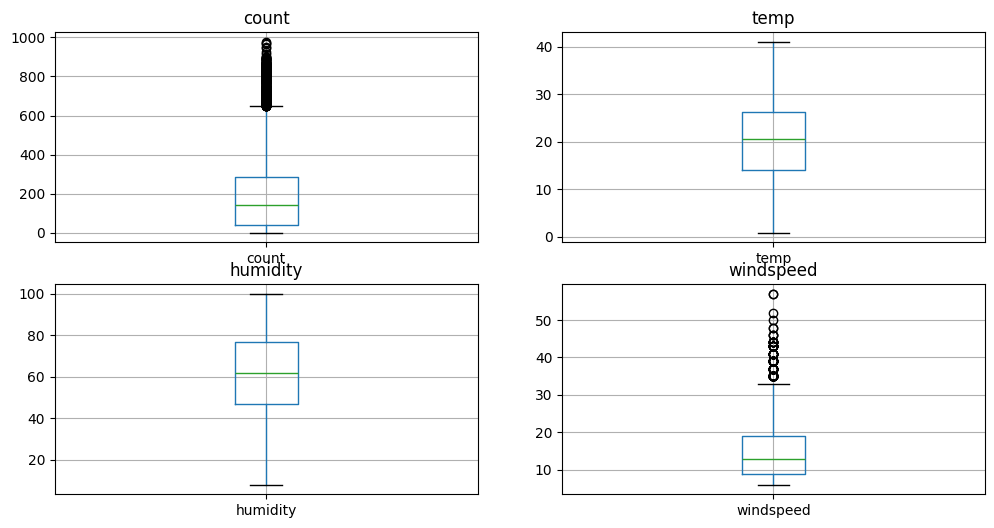

In [18]:
cols = ['count', 'temp', 'humidity', 'windspeed']
plt.figure(figsize=(12,6))
for col in cols:
  plt.subplot(2,2,cols.index(col)+1)
  df.boxplot(column=col)
  plt.title(col)
plt.show()

In [19]:
Q1 = df['count'].quantile(0.25)
Q3 = df['count'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
n = (df['count'] > upper_bound).sum()
cleaning.append(['Outliers de count (max 977)', 'Valla superior 647', 'Conservar y aplicar log1p al target', n])
print('Valla superior:', upper_bound)
print('Filas por encima:', n)

Valla superior: 647.0
Filas por encima: 300


300 horas superan la valla superior del IQR (647 alquileres). No se eliminan porque son picos reales de demanda (horas pico de días laborales con buen clima), justo lo que el modelo tiene que aprender. En lugar de recortarlos se aplica `log1p` al target, que reduce su peso.

### 3.7 Resumen de la limpieza

In [20]:
cleaning = pd.DataFrame(cleaning, columns=['Problema', 'Conteo 1er corte', 'Tratamiento', 'Filas afectadas'])
cleaning

,Problema,Conteo 1er corte,Tratamiento,Filas afectadas
0,weather = 4 (tormenta),1 fila,Unir con la categoria 3,1
1,datetime como texto,1 columna,Convertir a fecha,0
2,season y weather son categorias guardadas como...,2 columnas,Convertir a texto para one-hot,0
3,windspeed = 0 (faltante disfrazado),1.313,Marcar como nulo e imputar con la mediana,1313
4,humidity = 0,22,Marcar como nulo e imputar con la mediana,22
5,Filas duplicadas,0,Ninguno,0
6,casual y registered (suman count),2 columnas,Eliminar,0
7,Outliers de count (max 977),Valla superior 647,Conservar y aplicar log1p al target,300


In [21]:
print('Filas:', df.shape[0])
print('Columnas:', df.shape[1])

Filas: 10886
Columnas: 10


Quedan **10.886 filas y 10 columnas**: no se eliminó ninguna fila. Se corrigieron 1 categoría rara, 1.335 valores imposibles que pasan a imputarse y 2 tipos de dato, y se quitaron 2 columnas por fuga de información.

## 4. Análisis exploratorio de datos
Primero se extraen de la fecha la hora, el día de la semana, el mes y el año, porque el análisis los necesita.

In [22]:
df['hour'] = df['datetime'].dt.hour
df['dayofweek'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month
df['year'] = df['datetime'].dt.year
df[['datetime', 'hour', 'dayofweek', 'month', 'year']].head()

,datetime,hour,dayofweek,month,year
0,2011-01-01 00:00:00,0,5,1,2011
1,2011-01-01 01:00:00,1,5,1,2011
2,2011-01-01 02:00:00,2,5,1,2011
3,2011-01-01 03:00:00,3,5,1,2011
4,2011-01-01 04:00:00,4,5,1,2011


### 4.1 Univariado

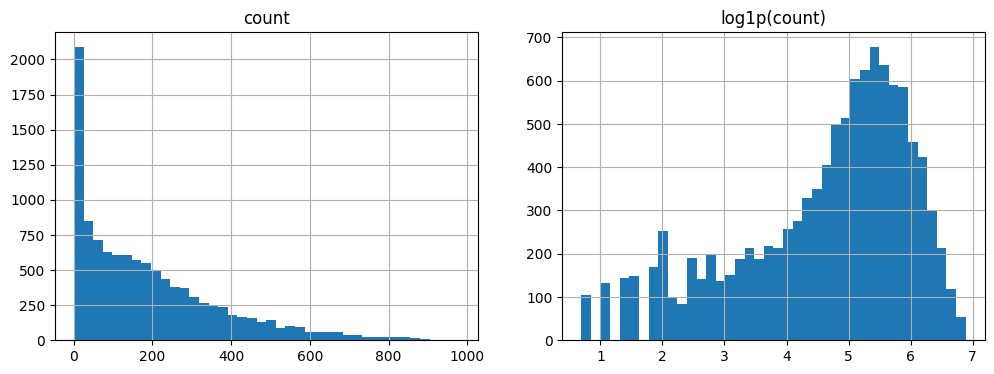

In [23]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
df['count'].hist(bins=40)
plt.title('count')
plt.subplot(1,2,2)
np.log1p(df['count']).hist(bins=40)
plt.title('log1p(count)')
plt.show()

In [24]:
print('Media:', df['count'].mean().round(1), '- Mediana:', df['count'].median())
print('Asimetria de count:', df['count'].skew().round(2))
print('Asimetria de log1p(count):', np.log1p(df['count']).skew().round(2))

Media: 191.6 - Mediana: 145.0
Asimetria de count: 1.24
Asimetria de log1p(count): -0.85


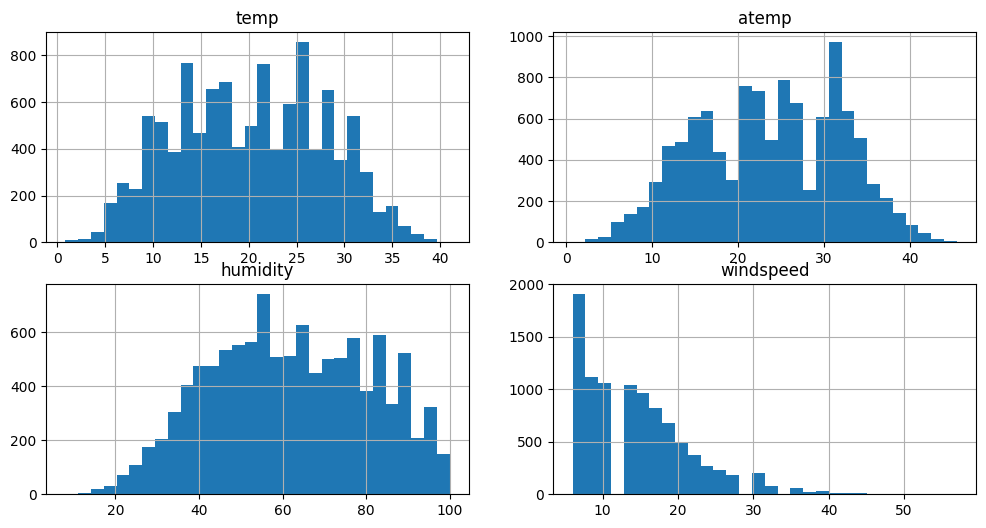

In [25]:
cols = ['temp', 'atemp', 'humidity', 'windspeed']
plt.figure(figsize=(12,6))
for col in cols:
  plt.subplot(2,2,cols.index(col)+1)
  df[col].hist(bins=30)
  plt.title(col)
plt.show()

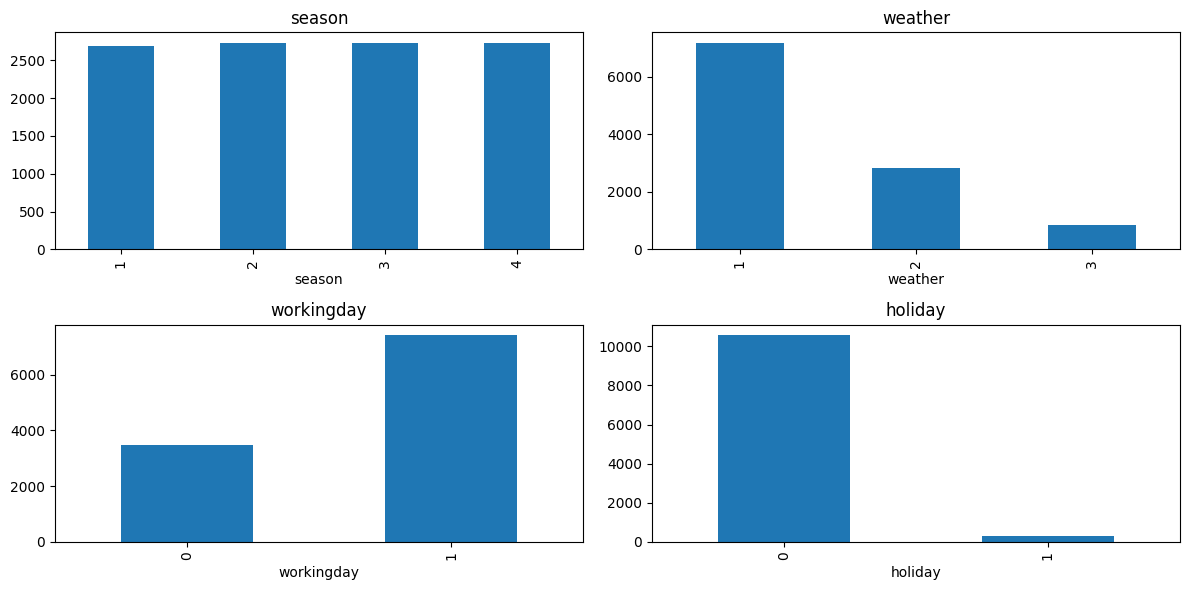

In [26]:
cols = ['season', 'weather', 'workingday', 'holiday']
plt.figure(figsize=(12,6))
for col in cols:
  plt.subplot(2,2,cols.index(col)+1)
  df[col].value_counts().sort_index().plot(kind='bar')
  plt.title(col)
plt.tight_layout()
plt.show()

**Hallazgos univariados**
- `count` tiene sesgo a la derecha (media 191,6 y mediana 145; asimetría 1,24). Con `log1p` la asimetría queda en -0,85: no es perfecta, pero los valores grandes pierden peso y el error pasa a medirse en términos relativos, que es lo que mide el RMSLE.
- `temp` y `atemp` tienen formas casi iguales, `humidity` va de 0 a 100 y `windspeed` tenía el pico en 0 ya corregido.
- Las cuatro estaciones tienen casi la misma cantidad de horas. El clima 1 (despejado) es el 66% de las horas y el 3 (lluvia) solo el 8%. El 68% de las horas son de días laborales y solo 311 de festivos.

### 4.2 Bivariado

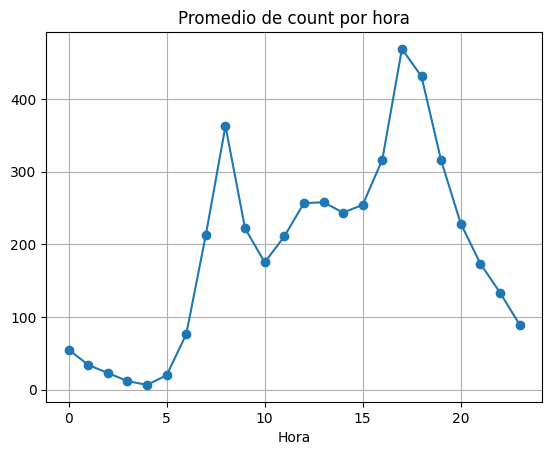

In [27]:
df.groupby('hour')['count'].mean().plot(marker='o')
plt.title('Promedio de count por hora')
plt.xlabel('Hora')
plt.grid()
plt.show()

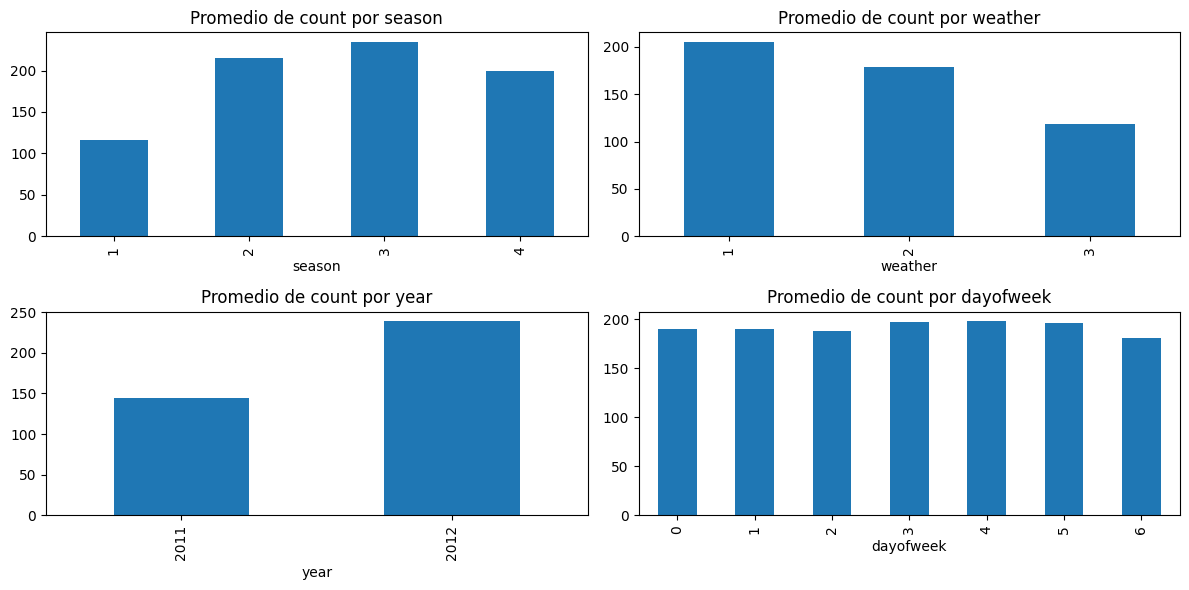

In [28]:
cols = ['season', 'weather', 'year', 'dayofweek']
plt.figure(figsize=(12,6))
for col in cols:
  plt.subplot(2,2,cols.index(col)+1)
  df.groupby(col)['count'].mean().plot(kind='bar')
  plt.title('Promedio de count por ' + col)
plt.tight_layout()
plt.show()

In [29]:
for col in ['season', 'weather', 'year', 'workingday']:
  print(df.groupby(col)['count'].mean().round(1).to_dict())

{'1': 116.3, '2': 215.3, '3': 234.4, '4': 199.0}
{'1': 205.2, '2': 179.0, '3': 118.9}
{2011: 144.2, 2012: 238.6}
{0: 188.5, 1: 193.0}


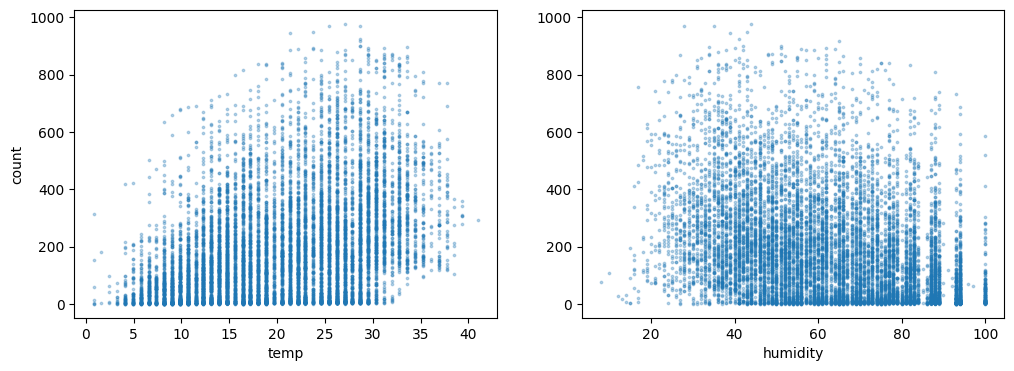

In [30]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.scatter(df['temp'], df['count'], s=3, alpha=0.3)
plt.xlabel('temp')
plt.ylabel('count')
plt.subplot(1,2,2)
plt.scatter(df['humidity'], df['count'], s=3, alpha=0.3)
plt.xlabel('humidity')
plt.show()

**Hallazgos bivariados**
- **Hora:** es lo que más cambia la demanda. Va de 6 bicicletas en promedio a las 4 a.m. a 469 a las 5 p.m.
- **Estación:** en primavera (season 1, enero a marzo en este dataset) se alquilan 116 por hora y en verano y otoño entre 215 y 234.
- **Clima:** con cielo despejado se alquilan 205 por hora y con lluvia 119.
- **Año:** 2012 tiene 239 por hora contra 144 de 2011; el sistema creció. Por eso el año entra como variable.
- **Temperatura y humedad:** más temperatura se asocia a más alquileres y más humedad a menos, pero con mucha dispersión.

### 4.3 Multivariado

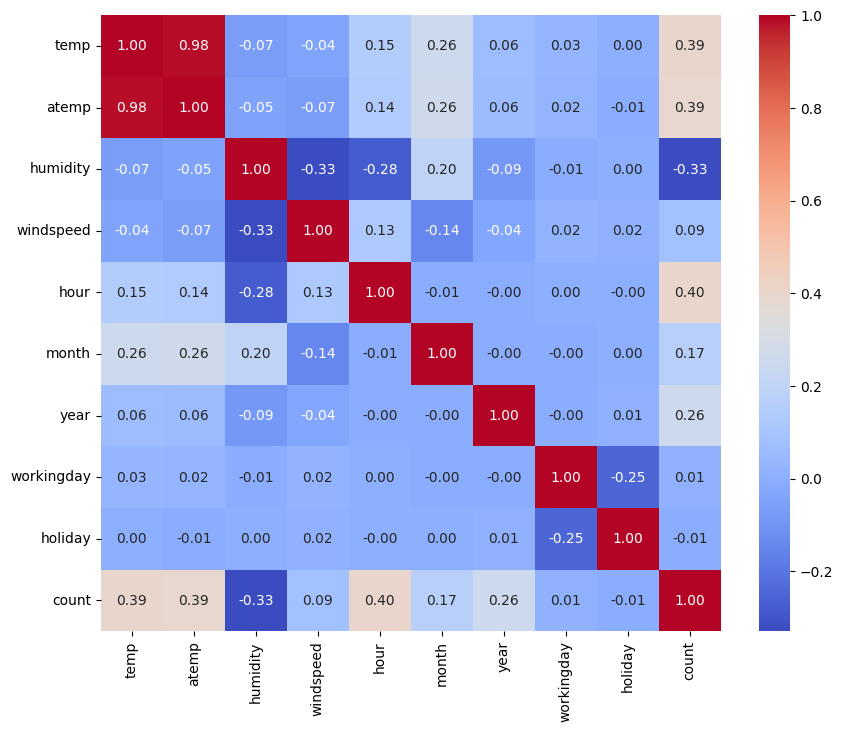

In [31]:
cols = ['temp', 'atemp', 'humidity', 'windspeed', 'hour', 'month', 'year', 'workingday', 'holiday', 'count']
plt.figure(figsize=(10,8))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [32]:
df[cols].corr()['count'].sort_values().round(2)

humidity     -0.33
holiday      -0.01
workingday    0.01
windspeed     0.09
month         0.17
year          0.26
atemp         0.39
temp          0.39
hour          0.40
count         1.00
Name: count, dtype: float64

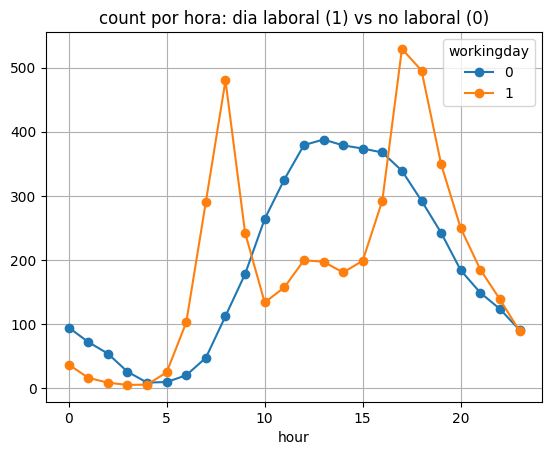

In [33]:
df.pivot_table(index='hour', columns='workingday', values='count', aggfunc='mean').plot(marker='o')
plt.title('count por hora: dia laboral (1) vs no laboral (0)')
plt.grid()
plt.show()

In [34]:
table = df.pivot_table(index='hour', columns='workingday', values='count', aggfunc='mean').round(0)
table.loc[[8, 13, 17, 18]]

workingday,0,1
hour,,
8,112.0,480.0
13,388.0,197.0
17,339.0,529.0
18,292.0,495.0


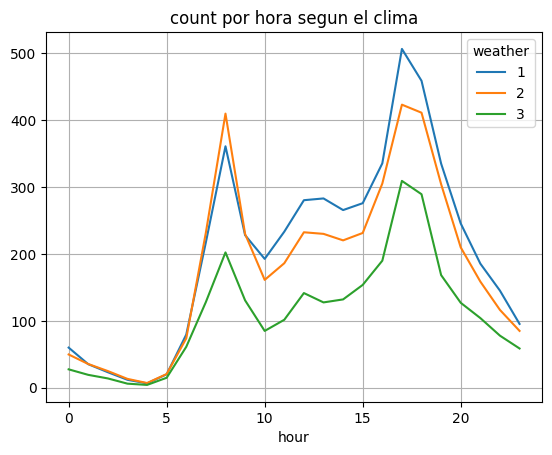

In [35]:
df.pivot_table(index='hour', columns='weather', values='count', aggfunc='mean').plot()
plt.title('count por hora segun el clima')
plt.grid()
plt.show()

**Hallazgos multivariados**
- **Correlaciones con count:** hora (+0,40), temp y atemp (+0,39), año (+0,26) y humedad (-0,33). `workingday` sale casi en 0 (+0,01), pero eso no significa que no importe.
- **temp y atemp:** correlación de 0,98. Por eso `atemp` se quita en el modelo lineal; los árboles no se afectan por eso.
- **Hora x día laboral:** en días laborales hay dos picos, a las 8 a.m. (480) y a las 5-6 p.m. (529), por los viajes al trabajo. En días no laborales la demanda sube al mediodía (388 a la 1 p.m. contra 197 en día laboral). Los dos efectos se cancelan en el promedio, por eso la correlación de `workingday` es casi 0.
- **Hora x clima:** la lluvia baja la demanda a todas las horas, pero la forma de la curva se mantiene.

**Qué decisiones apoyan**
- Las variables que se usan salen de aquí: hora, día de la semana, mes, año, estación, clima, temperatura, humedad, viento, festivo y día laboral.
- La relación con la hora no es lineal (dos picos) y depende del tipo de día. Un modelo lineal no puede representar eso; los modelos de árboles sí. Esto justifica comparar Ridge contra Random Forest y Gradient Boosting, como se propuso en el primer corte.

## 5. Ingeniería de variables
La hora es cíclica: las 23 h y las 0 h están juntas, pero como número están lejos. Se agregan el seno y el coseno de la hora para que el modelo lineal vea esa cercanía.

In [36]:
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df[['hour', 'hour_sin', 'hour_cos']].head(6)

,hour,hour_sin,hour_cos
0,0,0.000000,1.000000
1,1,0.258819,0.965926
2,2,0.500000,0.866025
3,3,0.707107,0.707107
4,4,0.866025,0.500000
5,5,0.965926,0.258819


In [37]:
numerical = ['temp', 'atemp', 'humidity', 'windspeed', 'hour', 'hour_sin', 'hour_cos', 'dayofweek', 'month', 'year']
binary = ['holiday', 'workingday']
categorical = ['season', 'weather']
numerical_linear = [col for col in numerical if col != 'atemp']
features = numerical + binary + categorical
print(len(features), features)

14 ['temp', 'atemp', 'humidity', 'windspeed', 'hour', 'hour_sin', 'hour_cos', 'dayofweek', 'month', 'year', 'holiday', 'workingday', 'season', 'weather']


Se usan 14 variables de entrada: 10 numéricas, 2 binarias (`holiday` y `workingday`, que ya son 0/1) y 2 categóricas para one-hot. Ridge usa las mismas pero sin `atemp`.

La división es **cronológica**: el 80% más antiguo para entrenar y el 20% más reciente para probar. Si se dividiera al azar, el modelo vería horas del mismo día en train y en test, y el resultado sería demasiado optimista para predecir el futuro.

In [38]:
X = df[features]
y = np.log1p(df['count'])
cut = int(len(df) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]
print('Train:', X_train.shape, df['datetime'].iloc[0], '-', df['datetime'].iloc[cut - 1])
print('Test:', X_test.shape, df['datetime'].iloc[cut], '-', df['datetime'].iloc[-1])

Train: (8708, 14) 2011-01-01 00:00:00 - 2012-08-05 04:00:00
Test: (2178, 14) 2012-08-05 05:00:00 - 2012-12-19 23:00:00


Train va de enero de 2011 a agosto de 2012 (8.708 horas) y test de agosto a diciembre de 2012 (2.178 horas).

El preprocesamiento va dentro de un `Pipeline`, como se propuso en el primer corte: imputación con la mediana y `StandardScaler` para las numéricas, las binarias sin cambios y one-hot para `season` y `weather`. Así todo se ajusta solo con train, y dentro de la validación cruzada se vuelve a ajustar en cada pliegue.

In [39]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA

In [40]:
def make_preprocessing(num_cols):
  return ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('bin', 'passthrough', binary),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
  ])

prep = make_preprocessing(numerical)
Z_train = prep.fit_transform(X_train)
print('Columnas despues del preprocesamiento:', Z_train.shape[1])
print('Mediana de windspeed (solo train):', prep.named_transformers_['num'].named_steps['imputer'].statistics_[numerical.index('windspeed')])

Columnas despues del preprocesamiento: 19
Mediana de windspeed (solo train): 12.998


## 6. Reducción de dimensionalidad: PCA
**Por qué.** Después del one-hot quedan 19 columnas y varias están muy relacionadas (temp con atemp, hora con su seno y coseno, mes con estación). PCA las combina en componentes no correlacionados y permite probar si el modelo funciona igual con menos columnas. LDA no se usa porque solo sirve para clasificación y este problema es de regresión.

In [41]:
pca = PCA()
pca.fit(Z_train)
variance = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(variance >= 0.95) + 1
print('Componentes para el 95%:', n_components, 'de', Z_train.shape[1])
print('Varianza explicada:', variance[n_components - 1])
print(np.round(variance, 3))

Componentes para el 95%: 10 de 19
Varianza explicada: 0.9560351301784064
[0.226 0.414 0.532 0.634 0.732 0.8   0.859 0.906 0.932 0.956 0.973 0.983
 0.99  0.997 0.998 0.999 1.    1.    1.   ]


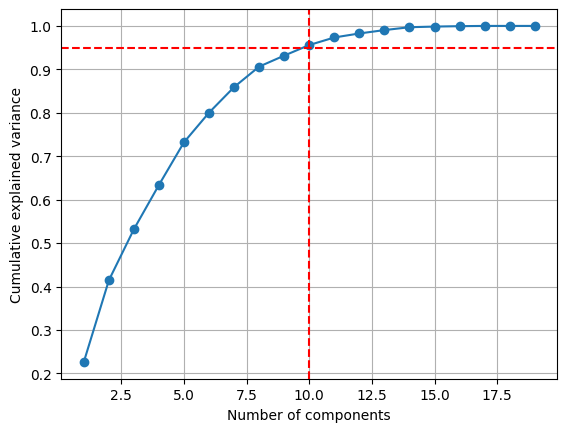

In [42]:
plt.plot(range(1, len(variance) + 1), variance, marker='o')
plt.axhline(0.95, color='red', linestyle='--')
plt.axvline(n_components, color='red', linestyle='--')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.grid()
plt.show()

In [43]:
names = prep.get_feature_names_out()
loadings = pd.DataFrame(pca.components_[:3].T, index=names, columns=['PC1', 'PC2', 'PC3'])
loadings.round(2)

,PC1,PC2,PC3
num__temp,0.56,0.16,0.25
num__atemp,0.56,0.17,0.25
num__humidity,-0.15,0.47,-0.16
num__windspeed,0.02,-0.34,0.01
num__hour,0.28,-0.42,-0.36
num__hour_sin,-0.31,0.43,0.34
num__hour_cos,-0.13,0.16,-0.21
num__dayofweek,-0.03,-0.01,-0.06
num__month,0.31,0.37,-0.36
num__year,-0.03,-0.19,0.63


Se necesitan **10 componentes de 19 para conservar el 95,6% de la varianza**. PC1 junta sobre todo la temperatura (temp y atemp con 0,56 cada una), PC2 mezcla humedad, hora y mes, y PC3 tiene mucho peso en el año. El efecto de PCA sobre los modelos se mide en la sección 7, entrenando cada modelo con y sin PCA.

## 7. Modelado
**Modelos (los del primer corte):**
- **Ridge:** regresión lineal con regularización. Es la línea base interpretable.
- **Random Forest:** muchos árboles que promedian sus predicciones. No supone linealidad y capta interacciones como hora x día laboral.
- **Gradient Boosting:** árboles que se entrenan uno tras otro, cada uno corrigiendo los errores del anterior. Suele ser de los mejores en datos tabulares.

**Entrenamiento.** `GridSearchCV` con `TimeSeriesSplit` de 5 pliegues sobre train: en cada pliegue se entrena con el pasado y se valida con el periodo siguiente. El modelo aprende `log1p(count)` y se optimiza el RMSE en esa escala, que es el RMSLE. El test solo se usa al final.

In [44]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [45]:
cv = TimeSeriesSplit(n_splits=5)
for i, (tr, va) in enumerate(cv.split(X_train)):
  print('Pliegue', i + 1, '- train:', len(tr), 'validacion:', len(va))

Pliegue 1 - train: 1453 validacion: 1451
Pliegue 2 - train: 2904 validacion: 1451
Pliegue 3 - train: 4355 validacion: 1451
Pliegue 4 - train: 5806 validacion: 1451
Pliegue 5 - train: 7257 validacion: 1451


In [46]:
models = {
  'Ridge': (Ridge(), numerical_linear, {'model__alpha': [0.1, 1, 10, 100]}),
  'Random Forest': (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), numerical, {'model__max_depth': [10, 20, None], 'model__min_samples_leaf': [1, 3]}),
  'Gradient Boosting': (GradientBoostingRegressor(random_state=42), numerical, {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 5]})
}

Las métricas se calculan en bicicletas (después de volver de la escala logarítmica con `expm1`): RMSE, MAE y MSE miden el error en bicicletas, R² cuánto de la variación se explica, y RMSLE el error relativo (la métrica de la competencia de Kaggle).

In [47]:
def metrics(y_true_log, y_pred_log):
  y_true = np.expm1(y_true_log)
  y_pred = np.clip(np.expm1(y_pred_log), 0, None)
  mse = mean_squared_error(y_true, y_pred)
  return {'RMSE': np.sqrt(mse), 'MAE': mean_absolute_error(y_true, y_pred), 'MSE': mse,
          'R2': r2_score(y_true, y_pred), 'RMSLE': np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))}

Cada modelo se entrena con y sin PCA. Esta celda tarda unos 7 minutos.

In [48]:
results = []
trained = {}

for reduction in ['Sin reduccion', 'PCA']:
  for name, (model, num_cols, grid) in models.items():
    steps = [('prep', make_preprocessing(num_cols))]
    if reduction == 'PCA':
      steps.append(('pca', PCA(n_components=0.95)))
    steps.append(('model', model))
    search = GridSearchCV(Pipeline(steps), grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    trained[(name, reduction)] = best
    train_m = metrics(y_train, best.predict(X_train))
    test_m = metrics(y_test, best.predict(X_test))
    results.append({'Modelo': name, 'Reduccion': reduction, 'Hiperparametros': search.best_params_,
                    'RMSLE CV': -search.best_score_, 'RMSLE train': train_m['RMSLE'],
                    'RMSE': test_m['RMSE'], 'MAE': test_m['MAE'], 'MSE': test_m['MSE'], 'R2': test_m['R2'], 'RMSLE test': test_m['RMSLE']})
    print(name, '-', reduction, 'listo')

Ridge - Sin reduccion listo


Random Forest - Sin reduccion listo


Gradient Boosting - Sin reduccion listo


Ridge - PCA listo


Random Forest - PCA listo


Gradient Boosting - PCA listo


In [49]:
results = pd.DataFrame(results)
results.round(3)

,Modelo,Reduccion,Hiperparametros,RMSLE CV,RMSLE train,RMSE,MAE,MSE,R2,RMSLE test
0,Ridge,Sin reduccion,{'model__alpha': 100},0.860,0.818,176.831,118.888,31269.102,0.340,0.806
1,Random Forest,Sin reduccion,"{'model__max_depth': 20, 'model__min_samples_l...",0.491,0.114,82.525,53.740,6810.431,0.856,0.373
2,Gradient Boosting,Sin reduccion,"{'model__learning_rate': 0.1, 'model__max_dept...",0.419,0.274,65.765,41.175,4325.036,0.909,0.315
3,Ridge,PCA,{'model__alpha': 10},0.861,0.832,177.463,118.934,31493.098,0.335,0.807
4,Random Forest,PCA,"{'model__max_depth': None, 'model__min_samples...",0.789,0.186,159.031,100.607,25290.963,0.466,0.647
5,Gradient Boosting,PCA,"{'model__learning_rate': 0.05, 'model__max_dep...",0.753,0.407,145.045,92.300,21038.157,0.556,0.645


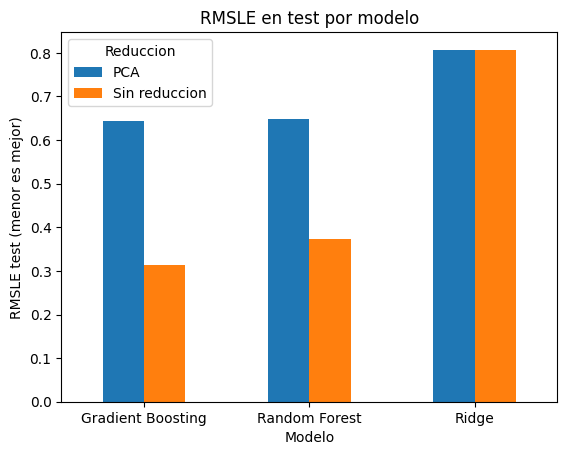

In [50]:
results.pivot_table(index='Modelo', columns='Reduccion', values='RMSLE test').plot(kind='bar')
plt.ylabel('RMSLE test (menor es mejor)')
plt.title('RMSLE en test por modelo')
plt.xticks(rotation=0)
plt.show()

## 8. Evaluación y resultados

### 8.1 Sobreajuste y subajuste

In [51]:
results['Brecha test - train'] = results['RMSLE test'] - results['RMSLE train']
results[['Modelo', 'Reduccion', 'RMSLE train', 'RMSLE CV', 'RMSLE test', 'Brecha test - train']].round(3)

,Modelo,Reduccion,RMSLE train,RMSLE CV,RMSLE test,Brecha test - train
0,Ridge,Sin reduccion,0.818,0.860,0.806,-0.012
1,Random Forest,Sin reduccion,0.114,0.491,0.373,0.259
2,Gradient Boosting,Sin reduccion,0.274,0.419,0.315,0.041
3,Ridge,PCA,0.832,0.861,0.807,-0.025
4,Random Forest,PCA,0.186,0.789,0.647,0.461
5,Gradient Boosting,PCA,0.407,0.753,0.645,0.238


- **Ridge:** el error de train (0,818) es casi igual al de test (0,806) y los dos son altos. Es **subajuste**: una línea no puede seguir la forma de dos picos de la demanda.
- **Random Forest:** RMSLE de 0,114 en train y 0,373 en test. Tiene **sobreajuste**: memoriza buena parte del entrenamiento.
- **Gradient Boosting:** 0,274 en train y 0,315 en test. La brecha es pequeña (0,04), es el modelo más equilibrado.
- El RMSLE de validación cruzada es mayor que el de test en todos los modelos porque en los primeros pliegues de `TimeSeriesSplit` el modelo entrena con muy pocos meses (el primero solo con 1.453 horas de inicio de 2011).

### 8.2 Mejor modelo

In [52]:
best_row = results[results['Reduccion'] == 'Sin reduccion'].sort_values(by='RMSLE CV').iloc[0]
best_model = trained[(best_row['Modelo'], best_row['Reduccion'])]
best_row

Modelo                                                 Gradient Boosting
Reduccion                                                  Sin reduccion
Hiperparametros        {'model__learning_rate': 0.1, 'model__max_dept...
RMSLE CV                                                        0.419234
RMSLE train                                                     0.273753
RMSE                                                           65.765009
MAE                                                            41.175302
MSE                                                          4325.036425
R2                                                              0.908655
RMSLE test                                                      0.314529
Brecha test - train                                             0.040776
Name: 2, dtype: object

In [53]:
baseline = np.full(len(y_test), y_train.mean())
print('Predecir siempre el promedio de train:', {k: round(v, 3) for k, v in metrics(y_test, baseline).items()})

Predecir siempre el promedio de train: {'RMSE': 277.166, 'MAE': 204.163, 'MSE': 76821.095, 'R2': -0.622, 'RMSLE': 1.441}


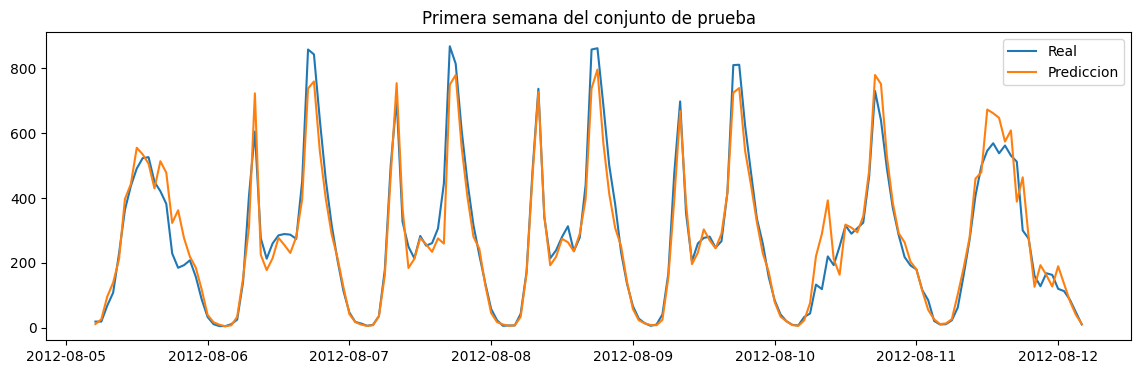

In [54]:
pred = np.clip(np.expm1(best_model.predict(X_test)), 0, None)
real = np.expm1(y_test)
week = slice(0, 24 * 7)
plt.figure(figsize=(14,4))
plt.plot(df['datetime'].iloc[cut:].iloc[week], real.iloc[week], label='Real')
plt.plot(df['datetime'].iloc[cut:].iloc[week], pred[week], label='Prediccion')
plt.title('Primera semana del conjunto de prueba')
plt.legend()
plt.show()

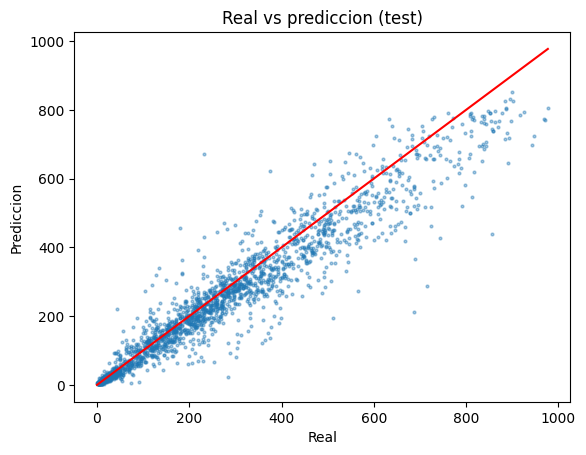

In [55]:
plt.scatter(real, pred, s=4, alpha=0.4)
plt.plot([0, real.max()], [0, real.max()], color='red')
plt.xlabel('Real')
plt.ylabel('Prediccion')
plt.title('Real vs prediccion (test)')
plt.show()

In [56]:
errors = real - pred
print('Error promedio por hora del dia:')
print(pd.Series(np.abs(errors.values)).groupby(X_test['hour'].values).mean().round(1).sort_values(ascending=False).head(5))

Error promedio por hora del dia:
17    111.4
18     89.3
8      84.2
16     74.2
7      66.6
dtype: float64


**Mejor modelo: Gradient Boosting sin reducción** (`n_estimators=400`, `learning_rate=0.1`, `max_depth=3`), elegido por tener el menor RMSLE en validación cruzada (0,419).

En test (agosto a diciembre de 2012): **R² 0,909**, RMSLE 0,315, RMSE 65,8 bicicletas, MAE 41,2 y MSE 4.325. En promedio se equivoca por unas 41 bicicletas por hora, cuando la demanda promedio es de 192. Predecir siempre el promedio daría RMSE 277 y RMSLE 1,44.

En la gráfica de la primera semana de test la predicción sigue los picos de la mañana y la tarde. Los errores más grandes están justo en las horas pico (5 p.m., 6 p.m. y 8 a.m.), que es donde la demanda es más alta y más variable.

### 8.3 Impacto de la reducción con PCA

In [57]:
results.pivot_table(index='Modelo', columns='Reduccion', values=['RMSLE test', 'R2']).round(3)

R2               RMSLE test              
Reduccion            PCA Sin reduccion        PCA Sin reduccion
Modelo                                                         
Gradient Boosting  0.556         0.909      0.645         0.315
Random Forest      0.466         0.856      0.647         0.373
Ridge              0.335         0.340      0.807         0.806

- **PCA empeora a los modelos de árboles:** el R² de Gradient Boosting baja de 0,909 a 0,556 y el de Random Forest de 0,856 a 0,466.
- La razón es que la hora es la variable más importante y PCA la mezcla con temperatura, humedad y mes en cada componente. Los árboles funcionan dividiendo por una variable a la vez (por ejemplo "hora entre 7 y 9"), y con las componentes ya no pueden hacerlo.
- **Ridge casi no cambia** (R² de 0,340 a 0,335), porque PCA es una transformación lineal y Ridge ya trabaja con combinaciones lineales.
- **Conclusión:** con solo 19 columnas no hace falta reducir, y PCA quita la información que más le sirve a los mejores modelos. El modelo final va sin reducción.

### 8.4 Variables más importantes

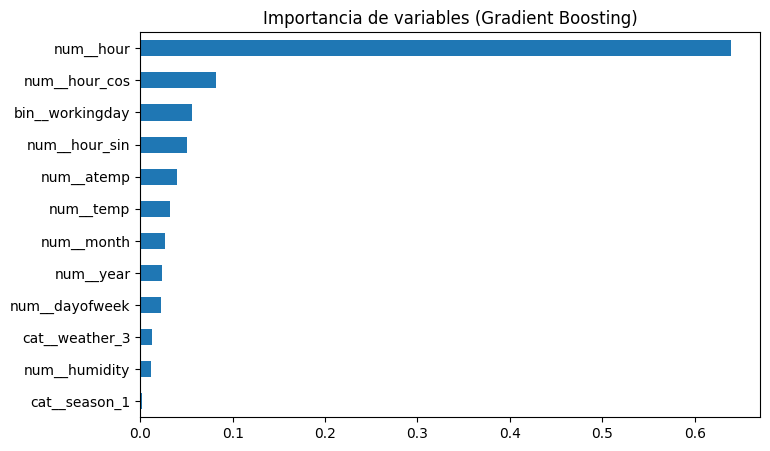

In [58]:
names = best_model.named_steps['prep'].get_feature_names_out()
importance = pd.Series(best_model.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False).head(12)
importance.sort_values().plot(kind='barh', figsize=(8,5))
plt.title('Importancia de variables (' + best_row['Modelo'] + ')')
plt.show()

La **hora** concentra el 64% de la importancia, y si se suman su seno y coseno pasa del 77%. Le siguen el día laboral (5,6%), la temperatura (temp y atemp suman 7%), el mes y el año. Coincide con el EDA: la demanda depende sobre todo de la hora y de si es día laboral, y después del clima y del crecimiento del sistema.

### 8.5 Conclusiones
- **Respuesta al problema:** sí se puede estimar la demanda por hora con buena precisión. El modelo explica el 91% de la variación y se equivoca en promedio por unas 41 bicicletas por hora.
- **Uso:** sirve para planear cuántas bicicletas tener en cada franja horaria y cuándo redistribuirlas, sobre todo antes de los picos de las 8 a.m. y las 5-6 p.m. de los días laborales.
- Los modelos de árboles superan claramente al lineal (R² de 0,909 y 0,856 contra 0,340), como anticipaba la relación no lineal entre la hora y la demanda. PCA no ayudó.

### 8.6 Limitaciones y mejoras
- **Una sola ciudad y dos años:** el sistema estaba creciendo (2012 tuvo un 65% más de alquileres que 2011), y el modelo no sabe cuánto va a crecer en años futuros.
- **Faltan variables:** no hay eventos, festivos locales ni ubicación de estaciones. El modelo predice el total de la ciudad, no por estación.
- **Días incompletos:** el `train.csv` de Kaggle solo tiene los días 1 al 19 de cada mes.
- **Picos difíciles:** el error es mayor en las horas pico. Se podría probar con más hiperparámetros, con XGBoost, o con modelos separados para usuarios casuales y registrados.
- **Clima conocido de antemano:** el modelo usa el clima real de la hora; en la práctica habría que usar el pronóstico, que tiene su propio error.

## 9. Guardar el modelo para la aplicación
Se guarda en `models/modelo.joblib` el `Pipeline` completo del mejor modelo (imputación, escalado, one-hot y Gradient Boosting) junto con la lista de variables. Como el preprocesamiento va dentro del pipeline, la app solo tiene que calcular la hora, el día, el mes, el año y el seno y coseno de la hora, y el pipeline hace el resto igual que en el entrenamiento. También se guardan la tabla de resultados, las importancias y el periodo de test para la demostración.

In [59]:
import joblib
import os
os.makedirs('models', exist_ok=True)
joblib.dump({
  'model': best_model,
  'features': features,
  'model_name': best_row['Modelo'],
  'params': best_row['Hiperparametros'],
  'metrics': {k: float(best_row[k]) for k in ['RMSE', 'MAE', 'MSE', 'R2', 'RMSLE test']},
  'medians': {'windspeed': float(X_train['windspeed'].median()), 'humidity': float(X_train['humidity'].median())}
}, 'models/modelo.joblib', compress=3)
results.drop(columns=['Hiperparametros']).round(3).to_csv('models/resultados.csv', index=False)
pd.DataFrame({'variable': importance.index, 'importancia': importance.values}).to_csv('models/importancias.csv', index=False)

In [60]:
os.makedirs('data', exist_ok=True)
raw = pd.read_csv(url)
raw['datetime'] = pd.to_datetime(raw['datetime'])
raw = raw.sort_values('datetime').reset_index(drop=True)
raw.iloc[cut:].to_csv('data/muestra_test.csv', index=False)
raw.iloc[cut:].shape

(2178, 12)